我们主要使用Python来构建这些基础的量化模型，写库还是会用到C++等语言

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import *

首先是第一个获取数据，我们可以使用一些公开数据源，另外也可以使用离线数据，或者就是抛出不可用

In [ ]:
import tushare as ts
import akshare as ak

引用完这些基础库我们应该做一些变量的基础设置，统一放在前面方便更改

In [ ]:
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

TS_TOKEN = ' '
TS_CODE = ' '
START_DATE = ' '
END_DATE = ' '

In [ ]:
ts.set_token(TS_TOKEN)
pro = ts.pro_api()

df = pro.daily(ts_code=TS_CODE, start_date=START_DATE, end_date=END_DATE)

先不搞那些乱七八糟的获取数据，我们先集中于这些模型吧，第一个就是二叉树binomialtree model

In [ ]:
from numpy import zeros, maximum, power, sqrt, exp

def binomial_option(S, K, r, sigma, t, steps, kind='call', american=False, output=0):
    '''
    构建欧式看涨期权的二叉树
    
    Params
    ------
    S           int/float   标的现价
    K           int/float   行权价
    r           float       无风险利率
    sigma       float       波动率
    t           int/float   到期时间（年）
    steps       int         步数
    kind        str         'call' or 'put'
    american    bool        True=美式（可以提前行权）, False=欧式
    output      int         0=价格矩阵 1=到期损益 2=期权价值 3=Delta
    ------
    '''
    
    dt = t / steps
    u = exp(sigma * sqrt(dt))
    v = 1 / u
    p = (exp(r * dt) - v) / (u - v)
    df = exp(-r * dt)
    
    px = zeros((steps + 1, steps + 1))     # 标的价格
    cp = zeros((steps + 1, steps + 1))     # 到期内在价值
    V = zeros((steps + 1, steps + 1))      # 期权价值
    delta = zeros((steps + 1, steps + 1))  # Delta
    
    # 前向方程：逐节点算价格与内在价值
    for j in range(steps + 1):
        for i in range(j + 1):
            px[i, j] = S * power(u, j - i) * power(v, i)
            if kind == 'call':
                cp[i, j] = maximum(px[i, j] - K, 0)
            else:
                cp[i, j] = maximum(K - px[i, j], 0)
    
    # 后向方程：从到期日贴现回今天
    for j in range(steps, -1, -1):
        for i in range(j + 1):
            if j == steps:
                V[i, j] = cp[i, j]          # 到期日：期权价值=内在价值

                if kind == 'call':
                    delta[i, j] = 1.0 if px[i, j] >= K else 0.0
                else:
                    delta[i, j] = -1.0 if px[i, j] <= K else 0.0
                
            else:
                continuation_value = df * (p * V[i, j + 1] + (1 - p) * V[i + 1, j + 1])

                if american:
                    V[i, j] = maximum(continuation_value, cp[i, j])
                else:
                    V[i, j] = continuation_value

                delta[i, j] = (V[i, j + 1] - V[i + 1, j + 1]) / (px[i, j + 1] - px[i + 1, j + 1])
    
    results = (px, cp, V, delta)
    
    return results[output]

In [33]:
# 标的价格矩阵px，第j列是第j步的所有可能价格，第i行表示跌了i次，右上三角以外都是0
px = binomial_option(100, 100, 0.05, 0.2, 1, 4, output=0)
px

array([[100.        , 110.51709181, 122.14027582, 134.98588076,
        149.18246976],
       [  0.        ,  90.4837418 , 100.        , 110.51709181,
        122.14027582],
       [  0.        ,   0.        ,  81.87307531,  90.4837418 ,
        100.        ],
       [  0.        ,   0.        ,   0.        ,  74.08182207,
         81.87307531],
       [  0.        ,   0.        ,   0.        ,   0.        ,
         67.0320046 ]])

In [34]:
# 到期内在价格矩阵cp = max{S_T - K, 0}
cp = binomial_option(100, 100, 0.05, 0.2, 1, 4, output=1)
cp

array([[ 0.        , 10.51709181, 22.14027582, 34.98588076, 49.18246976],
       [ 0.        ,  0.        ,  0.        , 10.51709181, 22.14027582],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ]])

In [35]:
# 期权价格矩阵opx，左上角就是当天期权价格
opx = binomial_option(100, 100, 0.05, 0.2, 1, 4, output=2)
opx

array([[ 9.97052292, 15.92151924, 24.60928461, 36.22810071, 49.18246976],
       [ 0.        ,  3.31726113,  6.24569514, 11.75931176, 22.14027582],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ]])

In [36]:
# 对冲比率Delta
dlt = binomial_option(100, 100, 0.05, 0.2, 1, 4, output=3)
dlt

array([[0.62916377, 0.82942009, 1.        , 1.        , 1.        ],
       [0.        , 0.34455349, 0.58698679, 1.        , 1.        ],
       [0.        , 0.        , 0.        , 0.        , 1.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ]])

In [37]:
import matplotlib.pyplot as plt

def plot_binomial_tree(S, K, r, sigma, t, steps, kind='call', american=False, output=2, max_steps_plot=5):
    '''
    画出二叉树图（自动调用 binomial_option 获取数据）
    
    Params
    ------
    kind            str   'call' or 'put'
    american        bool  True=美式(可以提前行权), False=欧式
    output          int   0=价格 1=损益 2=期权价值 3=Delta
    max_steps_plot  int   最多画前几步（防止节点太密看不清）
    ------
    '''
    
    px    = binomial_option(S, K, r, sigma, t, steps, kind=kind, american=american, output=0)
    cp    = binomial_option(S, K, r, sigma, t, steps, kind=kind, american=american, output=1)
    V     = binomial_option(S, K, r, sigma, t, steps, kind=kind, american=american, output=2)
    delta = binomial_option(S, K, r, sigma, t, steps, kind=kind, american=american, output=3)
    
    output_matrix = (px, cp, V, delta)[output]
    output_name = ["Price", "Payoff", "Value", "Delta"][output]
    plot_steps = min(steps, max_steps_plot)

    fig, ax = plt.subplots(figsize=(10, 6))
    title_style = "American" if american else "European"
    ax.set_title(f"Binomial Tree ({kind.title()} - {title_style}) - {output_name}")
    
    for j in range(plot_steps + 1):
        for i in range(j + 1):
            x = j
            y = (j - 2 * i) / 2  # 神奇的Y轴坐标，让树散开
            node_text = f"S: {px[i, j]:.2f}\n{output_name}: {output_matrix[i, j]:.2f}"
            ax.text(x, y, node_text, ha="center", va="center", 
                    bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray"))
            
            # 画节点之间的连线
            if j < plot_steps:
                ax.plot([x, x + 1], [y, y + 0.5], "k-", lw=1) # 上行线
                ax.plot([x, x + 1], [y, y - 0.5], "k-", lw=1) # 下行线
                
    ax.set_xlim(-0.5, plot_steps + 0.5)
    ax.set_ylim(-plot_steps / 2 - 0.5, plot_steps / 2 + 0.5)
    ax.axis("off")
    plt.show()

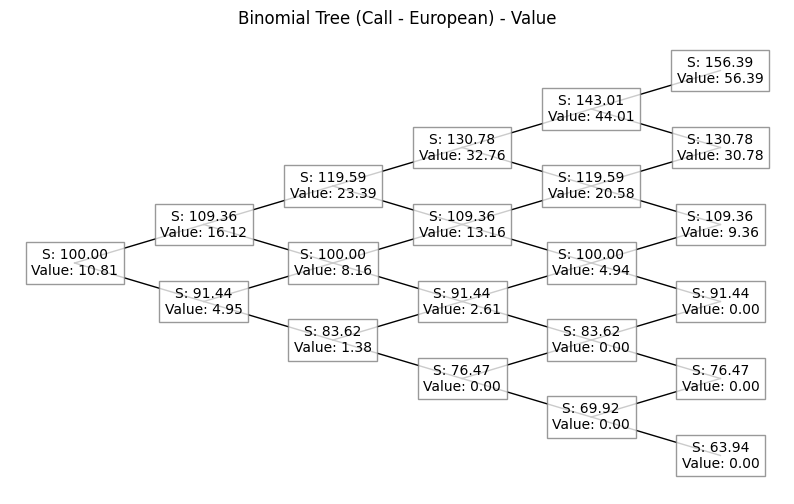

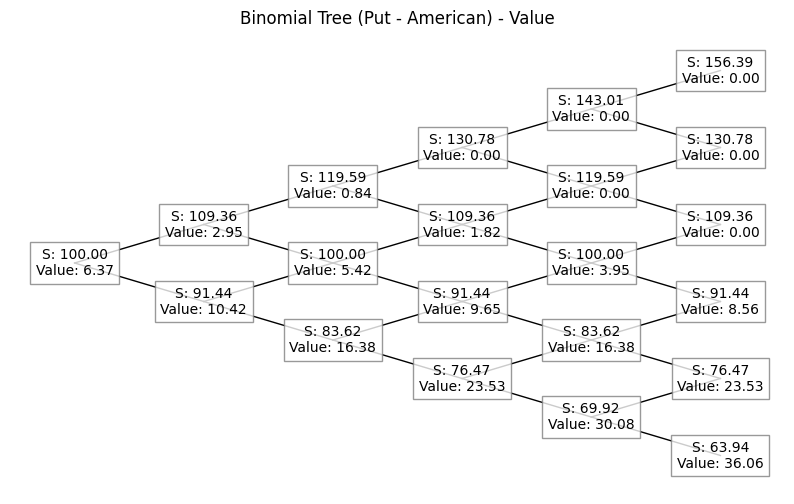

In [38]:
S, K, r, sigma, t = 100, 100, 0.05, 0.2, 1
plot_binomial_tree(S, K, r, sigma, t, steps=5, kind='call', american=False, output=2)
plot_binomial_tree(S, K, r, sigma, t, steps=5, kind='put', american=True, output=2)

In [39]:
eu_put = binomial_option(60, 100, 0.05, 0.2, 1, steps=500, kind='put', american=False, output=2)[0,0]
am_put = binomial_option(60, 100, 0.05, 0.2, 1, steps=500, kind='put', american=True, output=2)[0,0]

print(f"欧式Put价值: {eu_put:.4f}")
print(f"美式Put价值: {am_put:.4f}")
print(f"提前行权溢价: {am_put - eu_put:.4f}")

欧式Put价值: 35.1770
美式Put价值: 40.0000
提前行权溢价: 4.8230


In [40]:
def NormalCDF(x):
    return 0.5 * (1.0 + erf(x / sqrt(2.0)))

def black_scholes_option(S, K, r, sigma, t, kind, output=0):
    '''
    Black-Scholes欧式期权闭式解
    ------
    S       int/float   标的现价
    K       int/float   行权价
    r       float       无风险利率
    sigma   float       波动率
    t       int/float   到期时间（年）
    kind    str         'call'或'put'
    output  int         0=价格 1=Delta 2=Gamma 3=Vega 4=Theta 5=Rho
    ------
    '''
    if t <= 0:
        intrinsic = maximum(S - K, 0.0) if kind == 'call' else maximum(K - S, 0.0)
        delta_expiry = 1.0 if (kind == 'call' and S > K) else (-1.0 if(kind == 'put' and S < K) else 0.0)
        results = (intrinsic, delta_expiry, 0.0, 0.0, 0.0, 0.0)
        return results[output]
    
    d1 = (log(S / K) + (r + 0.5 * sigma ** 2) * t) / (sigma * sqrt(t))
    d2 = d1 - sigma * sqrt(t)
    df = exp(-r * t)
    pdf_d1 = exp(-0.5 * d1 * d1) / sqrt(2 * pi)
    
    if kind == 'call':
        price = S * NormalCDF(d1) - K * df * NormalCDF(d2)
        delta = NormalCDF(d1)
        rho = K * t * df * NormalCDF(d2)
        theta = (-S * pdf_d1 * sigma / (2 * sqrt(t)) - r * K * df * NormalCDF(d2))
    else:
        price = K * df * NormalCDF(-d2) - S * NormalCDF(-d1)
        delta = NormalCDF(d1) - 1.0
        rho   = -K * t * df * NormalCDF(-d2)
        theta = (-S * pdf_d1 * sigma / (2 * sqrt(t)) + r * K * df * NormalCDF(-d2))
    
    gamma = pdf_d1 / (S * sigma * sqrt(t))
    vega  = S * pdf_d1 * sqrt(t)

    results = (price, delta, gamma, vega, theta, rho)
    
    return results[output]